# VaR & CVaR (Expected Shortfall) — version desk

**Objectif** : passer d'un calcul pédagogique à un *moteur de risque* utilisable dans un terminal : plusieurs estimateurs, un vrai **backtesting statistique**, la **décomposition du risque** par ligne, des stress-tests et un export JSON pour l'interface.

| Bloc | Contenu |
|---|---|
| 1-2 | Données, diagnostic des rendements (queues épaisses, clustering de volatilité) |
| 3 | Estimateurs : historique, normal, Student-t, Cornish-Fisher, EVT (GPD), EWMA, GJR-GARCH + FHS |
| 4 | Horizon > 1 jour : règle √T vs simulation |
| 5 | **Backtesting** : Kupiec, Christoffersen, feux Bâle, tests d'ES (Acerbi-Székely, McNeil-Frey) |
| 6 | Portefeuille : VaR/ES composantes (Euler), bénéfice de diversification, stress |
| 7 | Monte-Carlo correct (GBM vectorisé, erreur de simulation) |
| 8 | Sizing sur budget de risque, export JSON |

**Conventions** — VaR et ES sont des **pertes positives** en fraction de la valeur du portefeuille ; α est le niveau de confiance (0,99 ⇒ 1 % de queue) ; la prévision du jour *t* n'utilise que l'information ≤ *t−1*.

In [1]:
import os, sys, json, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, os.getcwd())
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

from quantdesk.data import load_prices, to_returns
from quantdesk import risk as rk
from quantdesk.style import apply_terminal_style, AMBER, CYAN, GREEN, RED, GREY, VIOLET
apply_terminal_style()
pd.options.display.float_format = "{:,.4f}".format

# ---------------- PARAMÈTRES ----------------
TICKERS = ["SPY", "TLT", "GLD", "XOM", "AAPL"]          # lignes du portefeuille
WEIGHTS = np.array([0.35, 0.25, 0.10, 0.15, 0.15])       # poids (somme = 1, long-only ici)
CAPITAL = 1_000_000                                      # valeur du portefeuille
ALPHAS  = [0.95, 0.975, 0.99]                            # 97,5 % = niveau ES de FRTB
START   = "2005-01-01"
WINDOW  = 750                                            # fenêtre glissante du backtest (~3 ans)

px, meta = load_prices(TICKERS, start=START, cache_dir="data_cache")
R  = to_returns(px)                                      # rendements simples journaliers par ligne
rp = (R * WEIGHTS).sum(axis=1).rename("portefeuille")    # portefeuille rebalancé chaque jour
print(f"Source des données : {meta['source'].upper()}  |  {R.index[0].date()} → {R.index[-1].date()}  |  {len(R)} jours")
if meta["source"] == "synthetic":
    print("⚠️  DONNÉES SYNTHÉTIQUES (pas d'accès réseau) : les chiffres valident le code, pas le marché. "
          "Relancer avec accès Internet pour utiliser yfinance.")

Source des données : SYNTHETIC  |  2005-01-04 → 2026-09-18  |  5664 jours
⚠️  DONNÉES SYNTHÉTIQUES (pas d'accès réseau) : les chiffres valident le code, pas le marché. Relancer avec accès Internet pour utiliser yfinance.


## 1. Définitions

Pour une perte $L$ à horizon donné : $\mathrm{VaR}_\alpha=\inf\{x:\ P(L\le x)\ge\alpha\}$ et
$\mathrm{ES}_\alpha=\mathbb E[L\mid L\ge \mathrm{VaR}_\alpha]=\frac1{1-\alpha}\int_\alpha^1 \mathrm{VaR}_u\,du$.

* La VaR est un **quantile** : elle ignore la taille des pertes au-delà. L'ES les moyenne, elle est **sous-additive** (cohérente) et c'est la mesure retenue par Bâle FRTB (97,5 %).
* Sous normalité : $\mathrm{VaR}_\alpha=-\mu+\sigma z_\alpha$ et $\mathrm{ES}_\alpha=-\mu+\sigma\,\varphi(z_\alpha)/(1-\alpha)$. Sous Student-t à $\nu$ ddl, l'ES a aussi une forme fermée (implémentée dans `risk.student_t_var_es`).
* **Piège d'échelle** : la règle $\sqrt h$ n'est valable que pour des rendements i.i.d. ; on la compare plus bas à une simulation.

## 2. Diagnostic des rendements — pourquoi la normale + variance constante ne suffit pas

,valeur
Vol annualisée,0.1745
Asymétrie,0.1300
Kurtosis excédentaire,3.9805
p Jarque-Bera (H0 normalité),0.0000
p Ljung-Box(10) sur r,0.0391
p Ljung-Box(10) sur r²,0.0000
p ARCH-LM(10),0.0000
Pire jour,-0.0651
Meilleur jour,0.1130


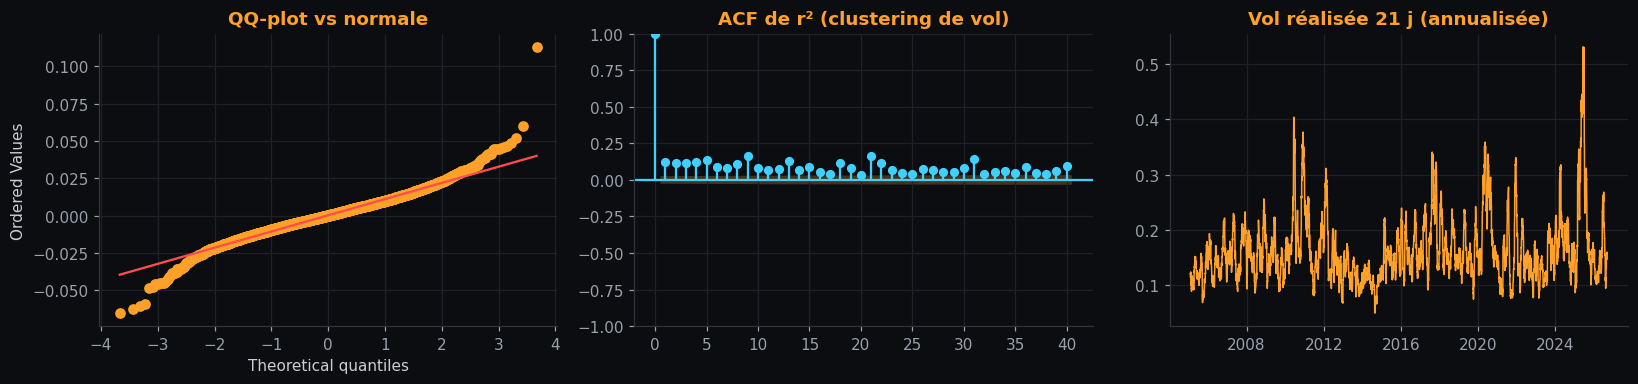

In [2]:
x = rp.dropna()
jb = stats.jarque_bera(x)
lb_r  = acorr_ljungbox(x,    lags=[10], return_df=True).iloc[0]
lb_r2 = acorr_ljungbox(x**2, lags=[10], return_df=True).iloc[0]
arch  = het_arch(x - x.mean(), nlags=10)
diag = pd.Series({
    "Vol annualisée": x.std()*np.sqrt(252), "Asymétrie": stats.skew(x), "Kurtosis excédentaire": stats.kurtosis(x),
    "p Jarque-Bera (H0 normalité)": jb.pvalue, "p Ljung-Box(10) sur r": lb_r["lb_pvalue"],
    "p Ljung-Box(10) sur r²": lb_r2["lb_pvalue"], "p ARCH-LM(10)": arch[1],
    "Pire jour": x.min(), "Meilleur jour": x.max()})
display(diag.to_frame("valeur"))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
stats.probplot(x, dist="norm", plot=ax[0]); ax[0].set_title("QQ-plot vs normale")
ax[0].get_lines()[0].set_color(AMBER); ax[0].get_lines()[1].set_color(RED)
plot_acf(x**2, lags=40, ax=ax[1], color=CYAN, vlines_kwargs={"colors": CYAN}); ax[1].set_title("ACF de r² (clustering de vol)")
ax[2].plot(x.rolling(21).std()*np.sqrt(252), color=AMBER, lw=1); ax[2].set_title("Vol réalisée 21 j (annualisée)")
plt.tight_layout(); plt.show()

**Lecture** — Une p-value JB ≈ 0 et un kurtosis excédentaire ≫ 0 signalent des queues épaisses ; une ACF de $r^2$ significative et un test ARCH-LM rejeté signalent du **clustering de volatilité**. Conséquence : un quantile *inconditionnel* sur-couvre en marché calme et sous-couvre en crise ; c'est ce que le backtest de la section 5 mesure.

## 3. Estimateurs de VaR / ES (1 jour, échantillon complet)

In [3]:
def all_static(r, alpha):
    out = {
        "Historique":         rk.hist_var_es(r, alpha),
        "Normal":             rk.normal_var_es(r, alpha),
        "Student-t (MLE)":    rk.student_t_var_es(r, alpha),
        "Cornish-Fisher":     rk.cornish_fisher_var_es(r, alpha),
        "EVT-POT (GPD 95%)":  rk.evt_pot_var_es(r, alpha),
        "GJR-GARCH + FHS":    rk.garch_fhs_next(r.iloc[-WINDOW:], alpha),
    }
    return pd.DataFrame(out).T[["VaR", "ES"]]

tabs = {a: all_static(rp, a) for a in ALPHAS}
static = pd.concat(tabs, axis=1)
static.columns = [f"{c} {a:.1%}" for a, c in static.columns]
display((static*100).round(3).rename_axis("% du portefeuille"))
display((static*CAPITAL).round(0).rename_axis(f"$ sur {CAPITAL:,.0f}"))

,VaR 95.0%,ES 95.0%,VaR 97.5%,ES 97.5%,VaR 99.0%,ES 99.0%
% du portefeuille,,,,,,
Historique,1.6779,2.3823,2.1004,2.8924,2.7426,3.6910
Normal,1.7797,2.2391,2.1262,2.5415,2.5289,2.9015
Student-t (MLE),1.7075,2.4065,2.1629,2.9050,2.7968,3.6203
Cornish-Fisher,1.6504,2.7972,2.3565,3.6370,3.4399,4.8844
EVT-POT (GPD 95%),1.6796,2.3859,2.1177,2.9020,2.7720,3.6728
GJR-GARCH + FHS,1.2985,1.9387,1.7109,2.4014,2.1059,3.0691


,VaR 95.0%,ES 95.0%,VaR 97.5%,ES 97.5%,VaR 99.0%,ES 99.0%
"$ sur 1,000,000",,,,,,
Historique,"16,779.0168","23,822.5847","21,003.5105","28,923.8527","27,426.0802","36,910.1695"
Normal,"17,797.3061","22,391.1503","21,261.5542","25,415.4240","25,289.4913","29,014.9071"
Student-t (MLE),"17,075.1464","24,065.3848","21,628.8367","29,049.9826","27,968.3218","36,202.5202"
Cornish-Fisher,"16,504.3550","27,971.8500","23,564.5586","36,370.1681","34,399.0727","48,843.5755"
EVT-POT (GPD 95%),"16,795.9245","23,858.6946","21,176.9011","29,019.9284","27,719.6639","36,727.9652"
GJR-GARCH + FHS,"12,985.4300","19,386.6325","17,109.3311","24,014.2878","21,059.4131","30,690.9116"


**À retenir** : les estimateurs divergent surtout sur l'**ES** et à 99 % ; l'écart *normal ↔ t/EVT* est la mesure directe du risque de modèle sur les queues. Le GARCH-FHS n'est pas comparable "toutes choses égales" : il est **conditionnel** (reflète la vol du jour), les autres sont inconditionnels sur la fenêtre.

In [4]:
# Paramètres de queue estimés (EVT) — ξ>0 : queue de type Pareto ; ξ<1 requis pour que l'ES existe
e = rk.evt_pot_var_es(rp, 0.99)
print(f"GPD : ξ = {e['xi']:.3f}, β = {e['beta']:.4f}   |   Student-t : ν = {rk.student_t_var_es(rp, 0.99)['nu']:.2f}")
cf = rk.cornish_fisher_var_es(rp, 0.99)
print(f"Cornish-Fisher : domaine de validité respecté = {cf['valid']}  (sinon le quantile modifié n'est plus monotone)")

GPD : ξ = 0.151, β = 0.0060   |   Student-t : ν = 5.74
Cornish-Fisher : domaine de validité respecté = True  (sinon le quantile modifié n'est plus monotone)


## 4. Horizon > 1 jour : √T, historique chevauchant, simulation

In [5]:
H = 10
mu_d, cov_d = np.log1p(R).mean().values, np.log1p(R).cov().values
alpha = 0.99
sq_norm = rk.scale_horizon_sqrt(rk.normal_var_es(rp, alpha)["VaR"], H)
sq_hist = rk.scale_horizon_sqrt(rk.hist_var_es(rp, alpha)["VaR"], H)
over = rp.rolling(H).apply(lambda s: np.prod(1 + s) - 1).dropna()                 # rendements 10 j chevauchants
ov = rk.hist_var_es(over, alpha)
mc = rk.mc_portfolio_var_es(WEIGHTS, mu_d, cov_d, alpha, horizon=H, n_sims=200_000, dist="t", df=5)
h_tab = pd.DataFrame({"VaR": [sq_norm, sq_hist, ov["VaR"], mc["VaR"]], "ES": [np.nan, np.nan, ov["ES"], mc["ES"]]},
                     index=["Normal × √10", "Historique × √10", "Historique 10 j chevauchant", "Monte-Carlo t (10 pas)"])
display((h_tab*100).round(3).rename_axis("% — VaR/ES 99 % à 10 jours"))

,VaR,ES
% — VaR/ES 99 % à 10 jours,,
Normal × √10,7.9970,NaN
Historique × √10,8.6730,NaN
Historique 10 j chevauchant,8.6190,11.7440
Monte-Carlo t (10 pas),7.7920,9.1990


L'écart entre $\sqrt{10}\times$ VaR 1 j et l'estimation directe vient de l'autocorrélation et du clustering de volatilité. Les rendements chevauchants sont fortement dépendants : peu d'observations *indépendantes* réelles (≈ N/10), donc une incertitude bien plus large que ne le suggère la taille de l'échantillon.

## 5. Volatilité conditionnelle et backtesting hors-échantillon

In [6]:
METHODS = ["hist", "normal", "cf", "t", "evt", "ewma", "garch_fhs"]
LABEL = {"hist":"Historique","normal":"Normal","cf":"Cornish-Fisher","t":"Student-t","evt":"EVT-POT","ewma":"EWMA λ=0,94","garch_fhs":"GJR-GARCH FHS"}
BT = {}
for a in (0.99, 0.975):
    BT[a] = {m: rk.rolling_var_es(rp, m, a, window=WINDOW) for m in METHODS}
print("Backtests calculés :", {a: len(next(iter(v.values()))) for a, v in BT.items()}, "observations OOS")

Backtests calculés : {0.99: 4914, 0.975: 4914} observations OOS


In [7]:
def pinball(bt, a):
    # perte de quantile (fonction de score cohérente pour la VaR) ; plus bas = meilleur
    tau, q, y = 1 - a, -bt["VaR"], bt["ret"]
    return float(np.mean((y - q) * (tau - (y < q).astype(float))))

summ = {}
for a in (0.99, 0.975):
    rows = {}
    for m in METHODS:
        s = rk.backtest_summary(BT[a][m], a); s["score_pinball_x1e4"] = pinball(BT[a][m], a)*1e4
        rows[LABEL[m]] = s
    summ[a] = pd.DataFrame(rows).T
for a in summ:
    print(f"\n=== α = {a:.1%} ===")
    display(summ[a])


=== α = 99.0% ===


,N,exceptions,attendues,taux,p_Kupiec,p_Christoffersen,p_CC,zone_Bâle(250j),Z2_ES,p_McNeilFrey,VaR_moy,ES_moy,score_pinball_x1e4
Historique,4914,70,49.1000,0.0142,0.0049,0.3689,0.0128,vert,0.4815,0.1422,0.0267,0.0344,3.9019
Normal,4914,81,49.1000,0.0165,0.0000,0.5854,0.0001,vert,0.9421,0.0000,0.0250,0.0286,3.9388
Cornish-Fisher,4914,44,49.1000,0.0090,0.4531,0.4139,0.5405,vert,-0.0241,0.0284,0.0299,0.0390,3.8759
Student-t,4914,66,49.1000,0.0134,0.0216,0.3019,0.0420,vert,0.4309,0.0398,0.0273,0.0348,3.8836
EVT-POT,4914,64,49.1000,0.0130,0.0418,0.8579,0.1239,vert,0.3584,0.1412,0.0276,0.0351,3.9240
"EWMA λ=0,94",4914,79,49.1000,0.0161,0.0001,0.1828,0.0002,vert,0.7615,0.0002,0.0248,0.0284,3.4536
GJR-GARCH FHS,4914,57,49.1000,0.0116,0.2718,0.1780,0.2207,vert,0.2508,0.0232,0.0259,0.0313,3.5117



=== α = 97.5% ===


,N,exceptions,attendues,taux,p_Kupiec,p_Christoffersen,p_CC,zone_Bâle(250j),Z2_ES,p_McNeilFrey,VaR_moy,ES_moy,score_pinball_x1e4
Historique,4914,138,122.9000,0.0281,0.1745,0.0070,0.0104,vert,0.1808,0.0454,0.0214,0.0283,7.6855
Normal,4914,154,122.9000,0.0313,0.0061,0.0041,0.0004,vert,0.4252,0.0000,0.0210,0.0251,7.6227
Cornish-Fisher,4914,122,122.9000,0.0248,0.9380,0.1205,0.2987,vert,0.0017,0.3780,0.0225,0.0310,7.5855
Student-t,4914,143,122.9000,0.0291,0.0726,0.0038,0.0030,vert,0.2252,0.0294,0.0214,0.0283,7.6318
EVT-POT,4914,143,122.9000,0.0291,0.0726,0.0011,0.0010,vert,0.2042,0.1172,0.0215,0.0285,7.7037
"EWMA λ=0,94",4914,144,122.9000,0.0293,0.0598,0.3999,0.1194,vert,0.2871,0.0002,0.0209,0.0249,7.0588
GJR-GARCH FHS,4914,135,122.9000,0.0275,0.2744,0.8782,0.5438,vert,0.1404,0.0692,0.0210,0.0266,7.1272


**Grille de lecture des tests**

* **Kupiec (POF)** : le taux d'exceptions est-il égal à $1-\alpha$ ? p < 5 % ⇒ modèle mal calibré (trop ou pas assez prudent).
* **Christoffersen (indépendance)** : les exceptions se regroupent-elles ? p < 5 % ⇒ le modèle réagit trop lentement aux changements de régime. **CC** = les deux à la fois.
* **Zone Bâle** (250 derniers jours) : vert < 95 % de la binomiale, jaune < 99,99 %, rouge au-delà ; le multiplicateur de capital augmente en zone jaune/rouge.
* **Z2 (Acerbi-Székely)** : espérance 0 si l'ES est correcte ; **> 0 ⇒ ES sous-estimée**. **McNeil-Frey** : test bootstrap sur les dépassements normalisés (H1 : ES sous-estimée).
* **Score pinball** : à couverture équivalente, *plus bas = VaR plus précise et moins gaspilleuse de capital* ; `VaR_moy` donne le coût en capital.

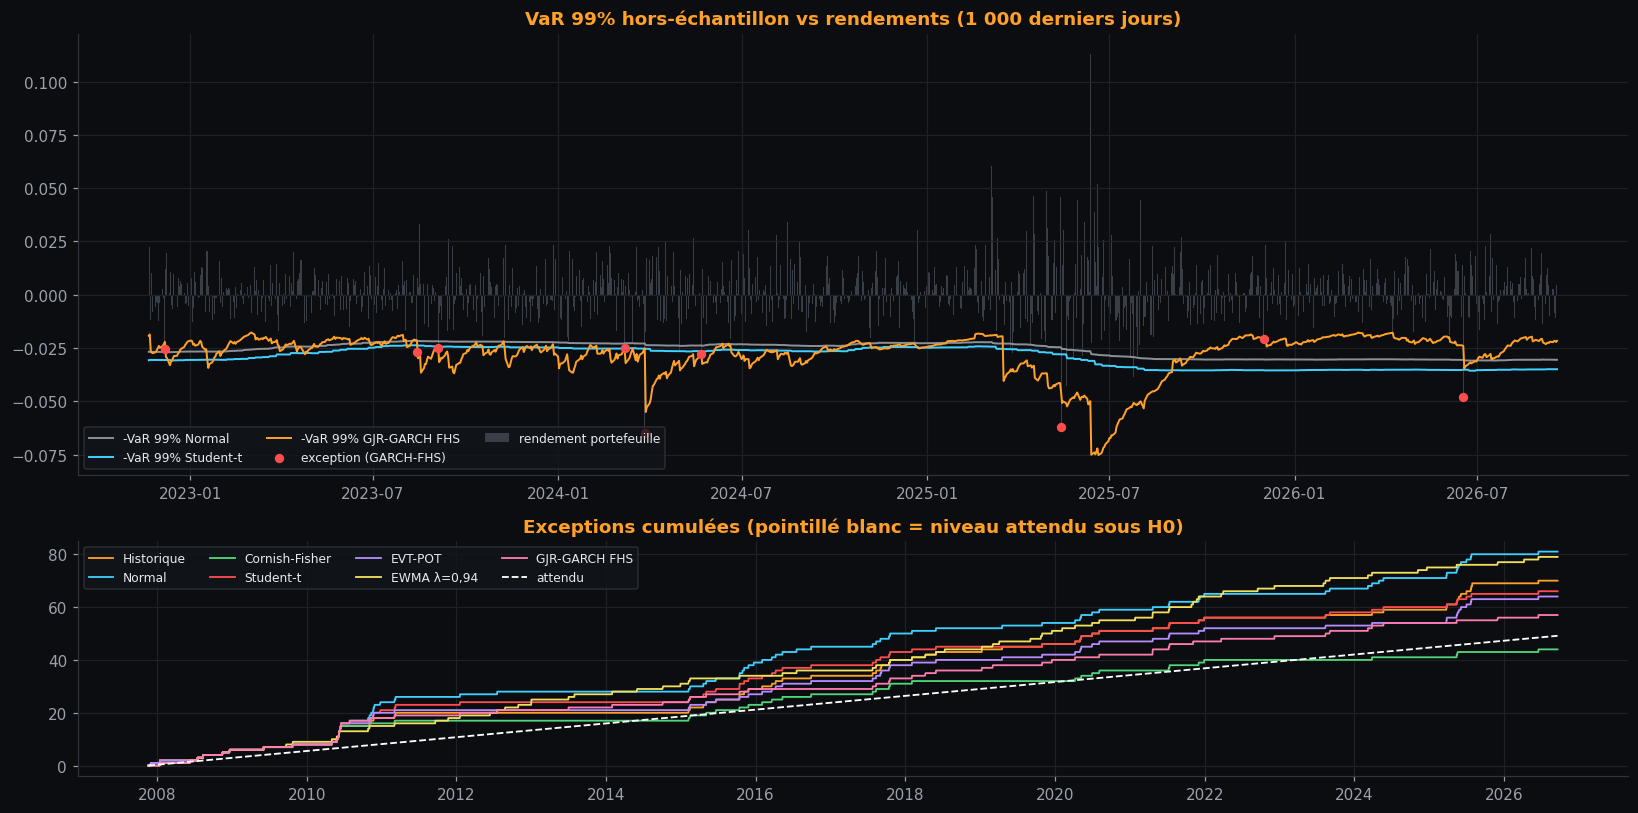

In [8]:
a = 0.99
fig, ax = plt.subplots(2, 1, figsize=(15, 7.5), gridspec_kw={"height_ratios": [3, 1.6]})
show = ["normal", "t", "garch_fhs"]; cols = {"normal": GREY, "t": CYAN, "garch_fhs": AMBER}
base = BT[a]["garch_fhs"]; zoom = base.index[-1000:]           # zoom sur ~4 ans pour la lisibilité
ax[0].bar(zoom, base.loc[zoom, "ret"], color="#3a3f47", width=1.0, label="rendement portefeuille")
for m in show:
    ax[0].plot(zoom, -BT[a][m].loc[zoom, "VaR"], color=cols[m], lw=1.3, label=f"-VaR {a:.0%} {LABEL[m]}")
exc = base.loc[zoom][base.loc[zoom, "hit"] == 1]
ax[0].scatter(exc.index, exc["ret"], color=RED, s=26, zorder=5, label="exception (GARCH-FHS)")
ax[0].legend(ncol=3, fontsize=8, loc="lower left"); ax[0].set_title(f"VaR {a:.0%} hors-échantillon vs rendements (1 000 derniers jours)")
for m in METHODS:
    ax[1].plot(BT[a][m]["hit"].cumsum(), lw=1.2, label=LABEL[m])
ax[1].plot(base.index, (1-a)*np.arange(1, len(base)+1), color="white", ls="--", lw=1.2, label="attendu")
ax[1].set_title("Exceptions cumulées (pointillé blanc = niveau attendu sous H0)"); ax[1].legend(ncol=4, fontsize=8)
plt.tight_layout(); plt.show()

**Ce que doit produire un bon moteur** : exceptions ≈ attendues (Kupiec non rejeté), pas de regroupement (Christoffersen non rejeté), Z2 proche de 0, et pinball bas. Les modèles **conditionnels** (EWMA, GARCH-FHS) sont ceux qui adaptent le niveau de VaR au régime de volatilité ; l'EWMA *normal* est souvent trop optimiste dans les queues (les innovations restent supposées gaussiennes) — le FHS corrige cela en rééchantillonnant les résidus standardisés observés.

## 6. Portefeuille : décomposition, diversification, stress

La VaR est **homogène de degré 1** ⇒ décomposition d'Euler : $\mathrm{VaR}=\sum_i w_i\,\partial\mathrm{VaR}/\partial w_i$. La contribution d'une ligne au risque n'est **pas** son poids.

In [9]:
cov_recent = R.iloc[-500:].cov().values                                 # 2 ans de covariance
dec = rk.parametric_risk_decomposition(WEIGHTS, cov_recent, 0.99, names=list(R.columns))
display((dec).round(4))

hdec = rk.historical_component_es(R.iloc[-1000:], WEIGHTS, 0.99)
print("\nES 99 % historique décomposé (4 dernières années, contributions exactes dans la queue du portefeuille) :")
display(hdec.round(4))

# bénéfice de diversification
standalone = np.array([rk.normal_var_es(R[c].iloc[-500:], 0.99)["VaR"] for c in R.columns]) * WEIGHTS
port = rk.normal_var_es((R.iloc[-500:] * WEIGHTS).sum(axis=1), 0.99)["VaR"]
print(f"\nΣ VaR stand-alone pondérées = {standalone.sum():.3%}  |  VaR portefeuille = {port:.3%}  |  bénéfice de diversification = {1-port/standalone.sum():.1%}")

,poids,VaR_marginale,VaR_composante,ES_composante,contrib_%
SPY,0.3500,0.0320,0.0112,0.0128,33.3582
TLT,0.2500,0.0330,0.0082,0.0094,24.5153
GLD,0.1000,0.0280,0.0028,0.0032,8.3231
XOM,0.1500,0.0396,0.0059,0.0068,17.6740
AAPL,0.1500,0.0361,0.0054,0.0062,16.1294
TOTAL,1.0000,NaN,0.0336,0.0385,100.0000



ES 99 % historique décomposé (4 dernières années, contributions exactes dans la queue du portefeuille) :


,poids,ES_contrib,contrib_%
SPY,0.3500,0.0135,32.7859
TLT,0.2500,0.0105,25.5754
GLD,0.1000,0.0033,7.9683
XOM,0.1500,0.0071,17.1705
AAPL,0.1500,0.0068,16.4999
TOTAL,1.0000,0.0412,100.0000



Σ VaR stand-alone pondérées = 3.515%  |  VaR portefeuille = 3.203%  |  bénéfice de diversification = 8.9%


In [10]:
# ---- Stress-tests : scénarios déterministes + pires fenêtres historiques
scen = {
    "Krach actions (−20 %)":       {"SPY":-.20, "XOM":-.25, "AAPL":-.28, "TLT": .06, "GLD": .04},
    "Choc de taux (+100 pb)":      {"TLT":-.08, "SPY":-.04, "AAPL":-.06, "GLD":-.03, "XOM": .00},
    "Stagflation":                 {"SPY":-.12, "TLT":-.10, "GLD": .10, "XOM": .08, "AAPL":-.15},
    "Choc pétrolier baissier":     {"XOM":-.25, "SPY":-.06, "TLT": .03, "GLD": .02, "AAPL":-.05},
}
shocks = {k: np.array([v.get(c, 0.0) for c in R.columns]) for k, v in scen.items()}
st = rk.stress_pnl(WEIGHTS, shocks)
worst = {f"Pire fenêtre {h} j (historique)": (rp.rolling(h).apply(lambda s: np.prod(1+s)-1)).min() for h in (1, 5, 21)}
tab = pd.concat([st, pd.Series(worst)]).to_frame("P&L")
tab["$"] = tab["P&L"] * CAPITAL
display(tab.rename_axis("Scénario"))

,P&L,$
Scénario,,
Krach actions (−20 %),-0.1305,"-130,500.0000"
Choc de taux (+100 pb),-0.0460,"-46,000.0000"
Stagflation,-0.0675,"-67,500.0000"
Choc pétrolier baissier,-0.0565,"-56,500.0000"
Pire fenêtre 1 j (historique),-0.0651,"-65,084.0118"
Pire fenêtre 5 j (historique),-0.1362,"-136,172.8153"
Pire fenêtre 21 j (historique),-0.2947,"-294,688.6963"


## 7. Monte-Carlo : ce qui était faux dans la version d'origine, et l'erreur de simulation

La marche aléatoire « à double choc » du notebook d'origine additionnait **deux** chocs indépendants de même écart-type $\sigma\sqrt{dt}$ : la variance journalière devient $2\sigma^2 dt$, donc une volatilité **√2 trop grande** (+41 %), qui gonfle artificiellement la VaR Monte-Carlo. Vérification numérique ci-dessous.

In [11]:
sigma_a, mu_a, S0, T = rp.std()*np.sqrt(252), rp.mean()*252, 100.0, 252
def walk_double_shock(n_paths, seed=1):       # reproduction du schéma d'origine (vectorisé)
    rng = np.random.default_rng(seed); dt = 1/252
    s = rng.normal(mu_a*dt, sigma_a*np.sqrt(dt), (n_paths, T)) + rng.normal(0, sigma_a*np.sqrt(dt), (n_paths, T))
    return S0*np.cumprod(1+s, axis=1)[:, -1]
paths = rk.simulate_gbm_paths(S0, mu_a, sigma_a, T, 20000, seed=1)
term_ok, term_bug = paths[:, -1], walk_double_shock(20000)
print(f"σ annualisée cible = {sigma_a:.3%} | σ des log-rendements terminaux : GBM correct = {np.log(term_ok/S0).std():.3%}, "
      f"double choc = {np.log(term_bug/S0).std():.3%}  (rapport {np.log(term_bug/S0).std()/np.log(term_ok/S0).std():.2f} ≈ √2)")

# VaR 1 an : simulation vs forme fermée lognormale
a = 0.99
closed = 1 - np.exp((mu_a - 0.5*sigma_a**2) + sigma_a*stats.norm.ppf(1-a))
mc_var = 1 - np.quantile(term_ok/S0, 1-a)
print(f"VaR {a:.0%} à 1 an : forme fermée = {closed:.3%} | simulation (20 000 trajectoires) = {mc_var:.3%}")

σ annualisée cible = 17.452% | σ des log-rendements terminaux : GBM correct = 17.498%, double choc = 24.696%  (rapport 1.41 ≈ √2)
VaR 99% à 1 an : forme fermée = 29.475% | simulation (20 000 trajectoires) = 29.519%


In [12]:
# Erreur de simulation : écart-type de la VaR MC selon le nombre de tirages (20 réplications par taille)
sizes = [1_000, 10_000, 100_000, 400_000]
res = {n: [rk.mc_portfolio_var_es(WEIGHTS, mu_d, cov_d, 0.99, 1, n, "t", 5, seed=s) for s in range(20)] for n in sizes}
err = pd.DataFrame({n: {"VaR moy": np.mean([o["VaR"] for o in v]), "VaR σ_MC": np.std([o["VaR"] for o in v]),
                        "ES moy": np.mean([o["ES"] for o in v]), "ES σ_MC": np.std([o["ES"] for o in v])} for n, v in res.items()}).T
err["σ_MC/VaR (%)"] = err["VaR σ_MC"]/err["VaR moy"]*100
display(err.rename_axis("n tirages"))

,VaR moy,VaR σ_MC,ES moy,ES σ_MC,σ_MC/VaR (%)
n tirages,,,,,
1000,0.0272,0.0025,0.0362,0.0044,9.3132
10000,0.0277,0.0007,0.0365,0.0011,2.5467
100000,0.0280,0.0002,0.0368,0.0004,0.6595
400000,0.0280,0.0001,0.0368,0.0002,0.3596


Règle desk : à 99 % l'erreur relative de la VaR décroît en $1/\sqrt{n}$ ; l'ES, calculée sur la queue seule, converge plus lentement. Toujours **reporter l'erreur Monte-Carlo** à côté du chiffre.

## 8. Sizing sur budget de risque et export vers le terminal

Position telle que la **perte de queue à 1 jour** égale un budget $b$ du capital : $\text{notionnel}=K\,b/\mathrm{ES}_{1j}$. Utiliser l'ES plutôt que la VaR rend le sizing sensible à la forme de la queue.

In [13]:
RISK_BUDGET = 0.01   # on accepte de perdre 1 % du capital dans la queue à 1 jour
rows = {}
for name, fn in {"Historique": rk.hist_var_es, "Normal": rk.normal_var_es, "Student-t": rk.student_t_var_es, "EVT": rk.evt_pot_var_es}.items():
    o = fn(rp, 0.99)
    rows[name] = {"VaR 99% 1j": o["VaR"], "ES 99% 1j": o["ES"],
                  "Notionnel (VaR)": rk.position_size(CAPITAL, RISK_BUDGET, o["VaR"]), "Notionnel (ES)": rk.position_size(CAPITAL, RISK_BUDGET, o["ES"])}
sz = pd.DataFrame(rows).T
sz["Levier (ES)"] = sz["Notionnel (ES)"]/CAPITAL
display(sz.round(4))

,VaR 99% 1j,ES 99% 1j,Notionnel (VaR),Notionnel (ES),Levier (ES)
Historique,0.0274,0.0369,"364,616.4506","270,928.0429",0.2709
Normal,0.0253,0.0290,"395,421.1603","344,650.4225",0.3447
Student-t,0.0280,0.0362,"357,547.3730","276,223.8632",0.2762
EVT,0.0277,0.0367,"360,754.7351","272,272.0943",0.2723


In [14]:
# ---------- export JSON pour l'interface (schéma stable) ----------
snap = {
    "meta": {"as_of": str(R.index[-1].date()), "source": meta["source"], "capital": CAPITAL, "tickers": list(R.columns), "weights": WEIGHTS.tolist()},
    "static_1d": {f"{a:.3f}": {m: {"VaR": float(tabs[a].loc[m, "VaR"]), "ES": float(tabs[a].loc[m, "ES"])} for m in tabs[a].index} for a in ALPHAS},
    "backtest_99": {k: {kk: (float(vv) if isinstance(vv, (int, float, np.floating, np.integer)) else str(vv)) for kk, vv in v.items()} for k, v in summ[0.99].T.to_dict().items()},
    "decomposition_normal_99": dec.drop("TOTAL")["VaR_composante"].to_dict(),
    "stress": tab["P&L"].to_dict(),
}
with open("risk_snapshot.json", "w") as f: json.dump(snap, f, indent=2, default=float)
print("risk_snapshot.json écrit :", os.path.getsize("risk_snapshot.json"), "octets")

risk_snapshot.json écrit : 6224 octets


## 9. Ce qui a été corrigé par rapport à la version d'origine

| # | Problème dans le notebook d'origine | Correction |
|---|---|---|
| 1 | Actifs incohérents (HAL / MSFT, titres de graphiques « Microsoft ») et fenêtre de vol de **50 jours** | Un portefeuille paramétrable, fenêtres explicites |
| 2 | Niveau `deg = 0.95` mais résultats étiquetés « 99 % » ; `percentile(5)` commenté « 1 % » | α unique et explicite, tables à 95 / 97,5 / 99 % |
| 3 | Marche aléatoire « double choc » ⇒ volatilité ×√2 | GBM vectorisé exact, vérifié contre la forme fermée |
| 4 | Horizons mélangés (1 j historique/paramétrique vs 252 j Monte-Carlo) et constantes codées en dur (`q = 39,31`, `41.5 - q`, `p = 24`) | Même horizon partout, section dédiée à l'échelle de temps |
| 5 | Loi de Student ajustée mais jamais utilisée ; conventions de signe mélangées | Student-t, Cornish-Fisher, EVT ; pertes toujours positives |
| 6 | Aucune volatilité conditionnelle, **aucun backtest** | EWMA, GJR-GARCH-FHS, Kupiec / Christoffersen / Bâle / tests d'ES |
| 7 | `round(x[0], 2)` dépend de la forme des Series yfinance (fragile) | Fonctions pures retournant des scalaires |
| 8 | Une seule ligne, pas de décomposition | VaR/ES composantes (Euler), diversification, stress |
| 9 | Pas d'erreur de simulation | Intervalle Monte-Carlo par taille d'échantillon |

**Limites à garder en tête** : VaR/ES paramétriques supposent des poids fixes (pas d'optionnalité ni de non-linéarité) ; pour des dérivés il faut revaloriser plein (full revaluation) ; la liquidité (horizons FRTB de 10 à 120 jours) n'est pas modélisée ici.